In [107]:

import torch
import torchvision
import numpy as np
import matplotlib.pyplot as plt

print("PyTorch sürümü:", torch.__version__)
print("Torchvision sürümü:", torchvision.__version__)
print("GPU kullanılabilir mi?:", torch.cuda.is_available())


PyTorch sürümü: 2.11.0+cpu
Torchvision sürümü: 0.26.0+cpu
GPU kullanılabilir mi?: False


In [108]:

from torchvision import datasets, transforms

transform = transforms.ToTensor()

train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

print("Eğitim verisi:", len(train_dataset))
print("Test verisi:", len(test_dataset))


Eğitim verisi: 60000
Test verisi: 10000


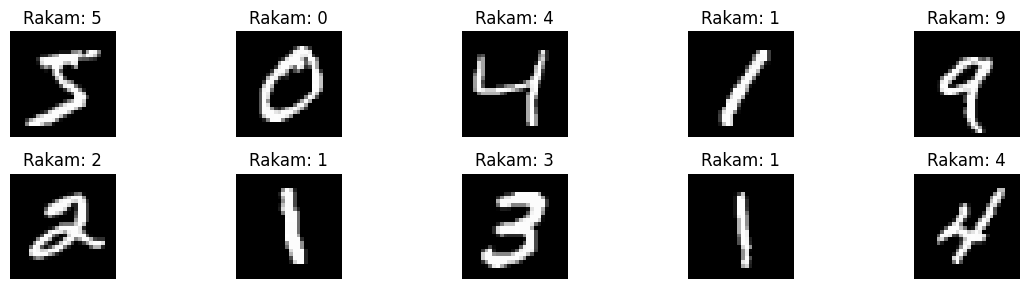

In [109]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 3))

for i in range(10):
    image, label = train_dataset[i]

    plt.subplot(2, 5, i + 1)
    plt.imshow(image.squeeze(), cmap="gray")
    plt.title(f"Rakam: {label}")
    plt.axis("off")

plt.tight_layout()
plt.show()


In [110]:

from torch.utils.data import random_split, DataLoader
import torch

# Sonuçların tekrarlanabilir olması için
torch.manual_seed(42)

# MNIST eğitim verisini ikiye ayırıyoruz
train_data, val_data = random_split(
    train_dataset,
    [50000, 10000],
    generator=torch.Generator().manual_seed(42)
)

# Her seferinde 64 görüntü işlenecek
batch_size = 64

# Eğitim verileri
train_loader = DataLoader(
    train_data,
    batch_size=batch_size,
    shuffle=True
)

# Doğrulama verileri
val_loader = DataLoader(
    val_data,
    batch_size=batch_size,
    shuffle=False
)

# Test verileri
test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)

print("Training:", len(train_data))
print("Validation:", len(val_data))
print("Test:", len(test_dataset))


Training: 50000
Validation: 10000
Test: 10000


In [111]:

import torch
import torch.nn as nn

# MLP modelimizi tanımlıyoruz
class MLP(nn.Module):

    def __init__(self):
        super(MLP, self).__init__()

        self.network = nn.Sequential(

            # 28x28 görüntüyü 784 elemanlı vektöre çevir
            nn.Flatten(),

            # 1. gizli katman
            nn.Linear(784, 128),
            nn.ReLU(),

            # 2. gizli katman
            nn.Linear(128, 64),
            nn.ReLU(),

            # Çıkış katmanı (10 rakam sınıfı)
            nn.Linear(64, 10)
        )

    def forward(self, x):
        return self.network(x)


# GPU varsa GPU, yoksa CPU kullan
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Modeli oluştur
model = MLP().to(device)

# Model mimarisini ekrana yazdır
print(model)
print("Kullanılan cihaz:", device)


MLP(
  (network): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=64, bias=True)
    (4): ReLU()
    (5): Linear(in_features=64, out_features=10, bias=True)
  )
)
Kullanılan cihaz: cpu


In [112]:

import torch.optim as optim

# Kayıp fonksiyonu
criterion = nn.CrossEntropyLoss()

# Optimizasyon algoritması
optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

# Eğitim turu sayısı
epochs = 10

print("Loss Function:", criterion)
print("Optimizer:", optimizer.__class__.__name__)
print("Learning Rate:", optimizer.param_groups[0]["lr"])
print("Epoch Sayısı:", epochs)


Loss Function: CrossEntropyLoss()
Optimizer: Adam
Learning Rate: 0.001
Epoch Sayısı: 10


In [113]:

import time

# Eğitim sonuçlarını saklayacağımız listeler
train_losses = []
val_losses = []
train_accuracies = []
val_accuracies = []

# Eğitim süresini ölçmeye başla
start_time = time.time()

for epoch in range(epochs):

    # -------- TRAINING --------
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        # Önceki gradyanları temizle
        optimizer.zero_grad()

        # Model tahminleri
        outputs = model(images)

        # Kayıp hesaplama
        loss = criterion(outputs, labels)

        # Geri yayılım
        loss.backward()

        # Ağırlıkları güncelle
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    train_loss = running_loss / total
    train_acc = 100 * correct / total

    # -------- VALIDATION --------
    model.eval()

    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_running_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)
            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)

    val_loss = val_running_loss / val_total
    val_acc = 100 * val_correct / val_total

    # Sonuçları kaydet
    train_losses.append(train_loss)
    val_losses.append(val_loss)
    train_accuracies.append(train_acc)
    val_accuracies.append(val_acc)

    print(
        f"Epoch [{epoch+1}/{epochs}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Train Acc: {train_acc:.2f}% | "
        f"Val Acc: {val_acc:.2f}%"
    )

# Toplam eğitim süresi
training_time = time.time() - start_time

print("\nEğitim tamamlandı!")
print(f"Toplam eğitim süresi: {training_time:.2f} saniye")


Epoch [1/10] Train Loss: 0.3682 | Val Loss: 0.2219 | Train Acc: 89.61% | Val Acc: 93.60%
Epoch [2/10] Train Loss: 0.1556 | Val Loss: 0.1490 | Train Acc: 95.34% | Val Acc: 95.62%
Epoch [3/10] Train Loss: 0.1082 | Val Loss: 0.1221 | Train Acc: 96.73% | Val Acc: 96.28%
Epoch [4/10] Train Loss: 0.0815 | Val Loss: 0.1086 | Train Acc: 97.48% | Val Acc: 96.74%
Epoch [5/10] Train Loss: 0.0630 | Val Loss: 0.1088 | Train Acc: 98.12% | Val Acc: 96.69%
Epoch [6/10] Train Loss: 0.0522 | Val Loss: 0.0994 | Train Acc: 98.38% | Val Acc: 96.97%
Epoch [7/10] Train Loss: 0.0410 | Val Loss: 0.0922 | Train Acc: 98.73% | Val Acc: 97.28%
Epoch [8/10] Train Loss: 0.0322 | Val Loss: 0.1184 | Train Acc: 98.99% | Val Acc: 96.75%
Epoch [9/10] Train Loss: 0.0268 | Val Loss: 0.1100 | Train Acc: 99.13% | Val Acc: 96.97%
Epoch [10/10] Train Loss: 0.0249 | Val Loss: 0.1113 | Train Acc: 99.18% | Val Acc: 97.26%

Eğitim tamamlandı!
Toplam eğitim süresi: 97.50 saniye


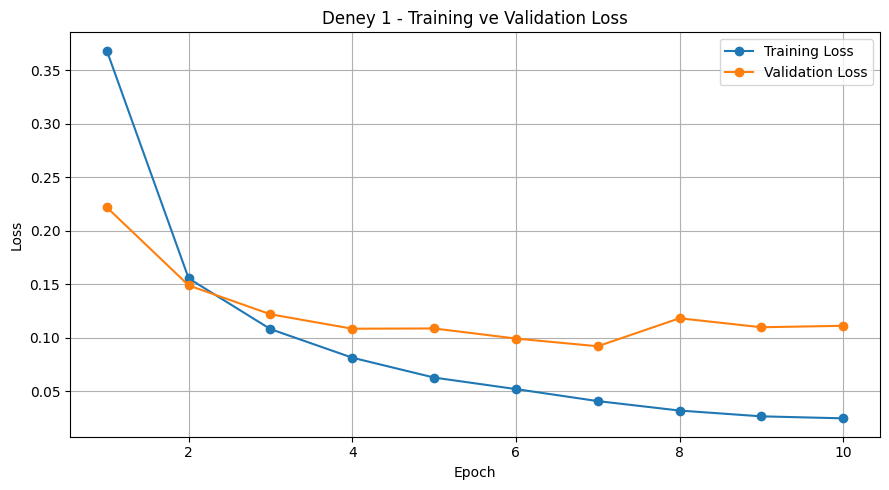

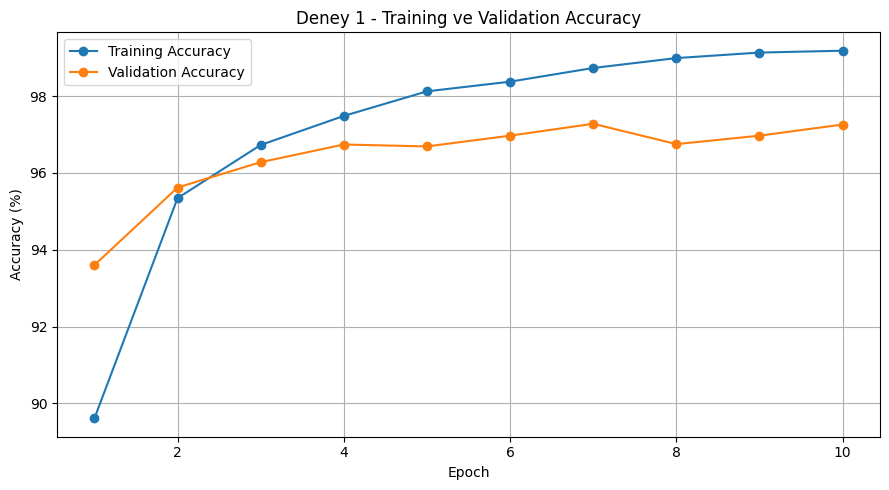

Grafikler results klasörüne kaydedildi.


In [114]:

import matplotlib.pyplot as plt
import os

# Grafiklerin kaydedileceği klasör
os.makedirs("results", exist_ok=True)

epoch_numbers = range(1, epochs + 1)

# LOSS GRAFİĞİ
plt.figure(figsize=(9, 5))

plt.plot(epoch_numbers, train_losses,
         marker="o", label="Training Loss")

plt.plot(epoch_numbers, val_losses,
         marker="o", label="Validation Loss")

plt.title("Deney 1 - Training ve Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig("results/experiment1_loss.png", dpi=300)
plt.show()

# ACCURACY GRAFİĞİ
plt.figure(figsize=(9, 5))

plt.plot(epoch_numbers, train_accuracies,
         marker="o", label="Training Accuracy")

plt.plot(epoch_numbers, val_accuracies,
         marker="o", label="Validation Accuracy")

plt.title("Deney 1 - Training ve Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig("results/experiment1_accuracy.png", dpi=300)
plt.show()

print("Grafikler results klasörüne kaydedildi.")


In [115]:

import pandas as pd

experiment1_results = pd.DataFrame({
    "Epoch": list(range(1, epochs + 1)),
    "Train Loss": train_losses,
    "Validation Loss": val_losses,
    "Train Accuracy": train_accuracies,
    "Validation Accuracy": val_accuracies
})

experiment1_results.to_csv(
    "results/experiment1_metrics.csv",
    index=False
)

print(experiment1_results.round(4).to_string(index=False))
print(f"\nEğitim süresi: {training_time:.2f} saniye")


 Epoch  Train Loss  Validation Loss  Train Accuracy  Validation Accuracy
     1      0.3682           0.2219          89.610                93.60
     2      0.1556           0.1490          95.344                95.62
     3      0.1082           0.1221          96.728                96.28
     4      0.0815           0.1086          97.484                96.74
     5      0.0630           0.1088          98.124                96.69
     6      0.0522           0.0994          98.376                96.97
     7      0.0410           0.0922          98.732                97.28
     8      0.0322           0.1184          98.990                96.75
     9      0.0268           0.1100          99.134                96.97
    10      0.0249           0.1113          99.182                97.26

Eğitim süresi: 97.50 saniye


In [116]:

import torch
import torch.nn as nn
import torch.optim as optim

# Deney 2: Daha fazla nöron içeren MLP
class MLP_Experiment2(nn.Module):

    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Flatten(),

            nn.Linear(784, 256),
            nn.ReLU(),

            nn.Linear(256, 128),
            nn.ReLU(),

            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.network(x)


# Tekrarlanabilirlik için
torch.manual_seed(42)

# İkinci model
model2 = MLP_Experiment2().to(device)

# Loss ve optimizer
criterion2 = nn.CrossEntropyLoss()

optimizer2 = optim.Adam(
    model2.parameters(),
    lr=0.001
)

print(model2)


MLP_Experiment2(
  (network): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=128, bias=True)
    (4): ReLU()
    (5): Linear(in_features=128, out_features=10, bias=True)
  )
)


In [117]:

import time
import copy

train_losses2 = []
val_losses2 = []
train_accuracies2 = []
val_accuracies2 = []

best_val_loss2 = float("inf")
best_epoch2 = 0
best_model_state2 = None

start_time2 = time.time()

for epoch in range(10):

    # TRAINING
    model2.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer2.zero_grad()

        outputs = model2(images)
        loss = criterion2(outputs, labels)

        loss.backward()
        optimizer2.step()

        running_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    train_loss = running_loss / total
    train_acc = 100 * correct / total

    # VALIDATION
    model2.eval()

    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model2(images)
            loss = criterion2(outputs, labels)

            val_running_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)
            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)

    val_loss = val_running_loss / val_total
    val_acc = 100 * val_correct / val_total

    # Sonuçları kaydet
    train_losses2.append(train_loss)
    val_losses2.append(val_loss)
    train_accuracies2.append(train_acc)
    val_accuracies2.append(val_acc)

    # En iyi modeli validation loss'a göre sakla
    if val_loss < best_val_loss2:
        best_val_loss2 = val_loss
        best_epoch2 = epoch + 1
        best_model_state2 = copy.deepcopy(model2.state_dict())

    print(
        f"Epoch [{epoch+1}/10] "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Train Acc: {train_acc:.2f}% | "
        f"Val Acc: {val_acc:.2f}%"
    )

training_time2 = time.time() - start_time2

print("\nDeney 2 tamamlandı!")
print(f"Eğitim süresi: {training_time2:.2f} saniye")
print(f"En iyi epoch: {best_epoch2}")
print(f"En düşük validation loss: {best_val_loss2:.4f}")

# En iyi ağırlıkları dosyaya kaydet
torch.save(
    best_model_state2,
    "results/experiment2_best_model.pth"
)


Epoch [1/10] Train Loss: 0.3157 | Val Loss: 0.1688 | Train Acc: 90.84% | Val Acc: 94.71%
Epoch [2/10] Train Loss: 0.1221 | Val Loss: 0.1218 | Train Acc: 96.33% | Val Acc: 96.29%
Epoch [3/10] Train Loss: 0.0785 | Val Loss: 0.0987 | Train Acc: 97.56% | Val Acc: 96.82%
Epoch [4/10] Train Loss: 0.0579 | Val Loss: 0.1101 | Train Acc: 98.22% | Val Acc: 96.77%
Epoch [5/10] Train Loss: 0.0429 | Val Loss: 0.0876 | Train Acc: 98.62% | Val Acc: 97.37%
Epoch [6/10] Train Loss: 0.0326 | Val Loss: 0.0938 | Train Acc: 98.99% | Val Acc: 97.35%
Epoch [7/10] Train Loss: 0.0262 | Val Loss: 0.0880 | Train Acc: 99.18% | Val Acc: 97.70%
Epoch [8/10] Train Loss: 0.0219 | Val Loss: 0.0978 | Train Acc: 99.27% | Val Acc: 97.45%
Epoch [9/10] Train Loss: 0.0197 | Val Loss: 0.1089 | Train Acc: 99.32% | Val Acc: 97.08%
Epoch [10/10] Train Loss: 0.0148 | Val Loss: 0.1038 | Train Acc: 99.49% | Val Acc: 97.54%

Deney 2 tamamlandı!
Eğitim süresi: 116.25 saniye
En iyi epoch: 5
En düşük validation loss: 0.0876


In [118]:

import pandas as pd

experiment2_results = pd.DataFrame({
    "Epoch": range(1, 11),
    "Train Loss": train_losses2,
    "Validation Loss": val_losses2,
    "Train Accuracy": train_accuracies2,
    "Validation Accuracy": val_accuracies2
})

experiment2_results.to_csv(
    "results/experiment2_metrics.csv",
    index=False
)

print(experiment2_results.round(4).to_string(index=False))


 Epoch  Train Loss  Validation Loss  Train Accuracy  Validation Accuracy
     1      0.3157           0.1688          90.844                94.71
     2      0.1221           0.1218          96.332                96.29
     3      0.0785           0.0987          97.556                96.82
     4      0.0579           0.1101          98.222                96.77
     5      0.0429           0.0876          98.624                97.37
     6      0.0326           0.0938          98.992                97.35
     7      0.0262           0.0880          99.176                97.70
     8      0.0219           0.0978          99.272                97.45
     9      0.0197           0.1089          99.324                97.08
    10      0.0148           0.1038          99.490                97.54


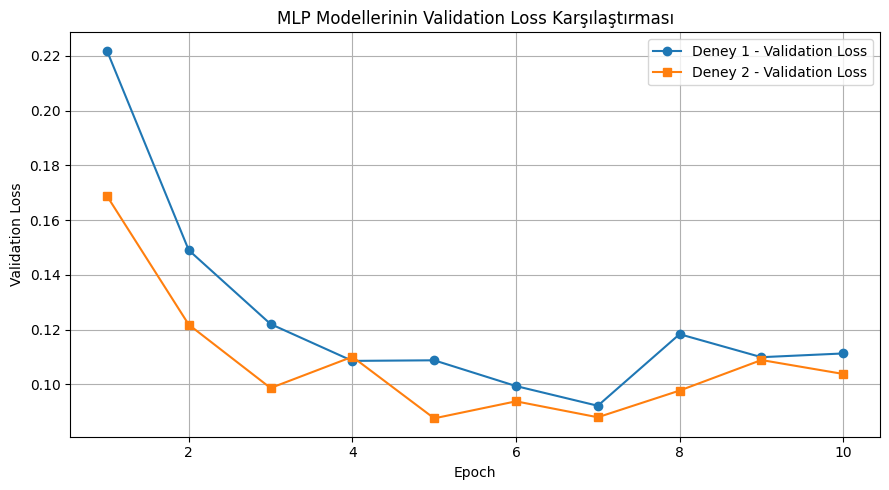

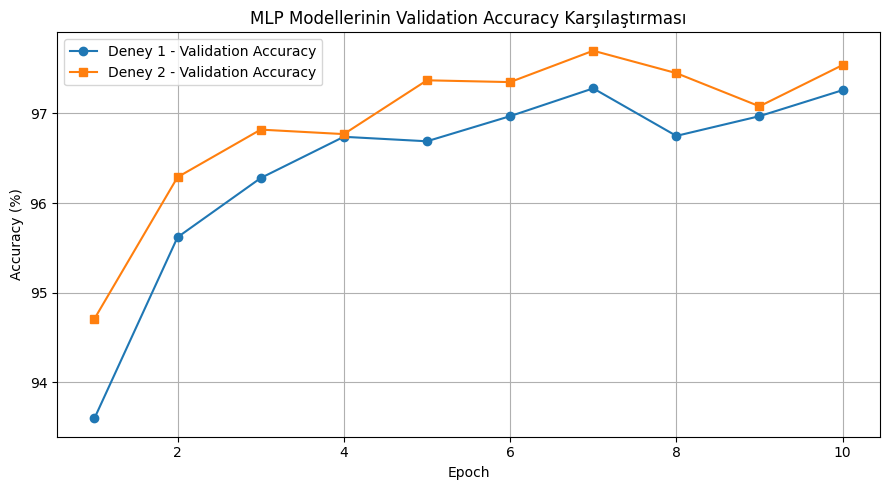

In [119]:

import matplotlib.pyplot as plt

epoch_numbers = range(1, 11)

# Validation Loss karşılaştırması
plt.figure(figsize=(9, 5))

plt.plot(epoch_numbers, val_losses,
         marker="o", label="Deney 1 - Validation Loss")

plt.plot(epoch_numbers, val_losses2,
         marker="s", label="Deney 2 - Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.title("MLP Modellerinin Validation Loss Karşılaştırması")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig("results/validation_loss_comparison.png", dpi=300)
plt.show()

# Validation Accuracy karşılaştırması
plt.figure(figsize=(9, 5))

plt.plot(epoch_numbers, val_accuracies,
         marker="o", label="Deney 1 - Validation Accuracy")

plt.plot(epoch_numbers, val_accuracies2,
         marker="s", label="Deney 2 - Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("MLP Modellerinin Validation Accuracy Karşılaştırması")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig("results/validation_accuracy_comparison.png", dpi=300)
plt.show()


In [120]:

# Deney 3 - Learning Rate Karşılaştırması

torch.manual_seed(42)

# Deney 2 ile aynı mimari
model3 = MLP_Experiment2().to(device)

# Loss fonksiyonu
criterion3 = nn.CrossEntropyLoss()

# Yalnızca learning rate değişiyor
optimizer3 = optim.Adam(
    model3.parameters(),
    lr=0.0005
)

print("Deney 3 modeli:")
print(model3)
print("Learning Rate:", optimizer3.param_groups[0]["lr"])


Deney 3 modeli:
MLP_Experiment2(
  (network): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=128, bias=True)
    (4): ReLU()
    (5): Linear(in_features=128, out_features=10, bias=True)
  )
)
Learning Rate: 0.0005


In [121]:

import time
import copy

train_losses3 = []
val_losses3 = []
train_accuracies3 = []
val_accuracies3 = []

best_val_loss3 = float("inf")
best_epoch3 = 0
best_model_state3 = None

start_time3 = time.time()

for epoch in range(10):

    # TRAINING
    model3.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer3.zero_grad()

        outputs = model3(images)
        loss = criterion3(outputs, labels)

        loss.backward()
        optimizer3.step()

        running_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    train_loss = running_loss / total
    train_acc = 100 * correct / total

    # VALIDATION
    model3.eval()

    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model3(images)
            loss = criterion3(outputs, labels)

            val_running_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)
            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)

    val_loss = val_running_loss / val_total
    val_acc = 100 * val_correct / val_total

    # Sonuçları sakla
    train_losses3.append(train_loss)
    val_losses3.append(val_loss)
    train_accuracies3.append(train_acc)
    val_accuracies3.append(val_acc)

    # En düşük validation loss'a sahip modeli kaydet
    if val_loss < best_val_loss3:
        best_val_loss3 = val_loss
        best_epoch3 = epoch + 1
        best_model_state3 = copy.deepcopy(model3.state_dict())

    print(
        f"Epoch [{epoch+1}/10] "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Train Acc: {train_acc:.2f}% | "
        f"Val Acc: {val_acc:.2f}%"
    )

training_time3 = time.time() - start_time3

print("\nDeney 3 tamamlandı!")
print(f"Eğitim süresi: {training_time3:.2f} saniye")
print(f"En iyi epoch: {best_epoch3}")
print(f"En düşük validation loss: {best_val_loss3:.4f}")

# En iyi model ağırlıklarını kaydet
torch.save(
    best_model_state3,
    "results/experiment3_best_model.pth"
)


Epoch [1/10] Train Loss: 0.3939 | Val Loss: 0.2192 | Train Acc: 89.07% | Val Acc: 93.36%
Epoch [2/10] Train Loss: 0.1652 | Val Loss: 0.1522 | Train Acc: 95.14% | Val Acc: 95.48%
Epoch [3/10] Train Loss: 0.1117 | Val Loss: 0.1176 | Train Acc: 96.72% | Val Acc: 96.35%
Epoch [4/10] Train Loss: 0.0831 | Val Loss: 0.1159 | Train Acc: 97.51% | Val Acc: 96.37%
Epoch [5/10] Train Loss: 0.0634 | Val Loss: 0.0941 | Train Acc: 98.05% | Val Acc: 97.03%
Epoch [6/10] Train Loss: 0.0489 | Val Loss: 0.0951 | Train Acc: 98.51% | Val Acc: 97.14%
Epoch [7/10] Train Loss: 0.0382 | Val Loss: 0.0925 | Train Acc: 98.85% | Val Acc: 97.14%
Epoch [8/10] Train Loss: 0.0295 | Val Loss: 0.0889 | Train Acc: 99.14% | Val Acc: 97.34%
Epoch [9/10] Train Loss: 0.0241 | Val Loss: 0.0989 | Train Acc: 99.29% | Val Acc: 97.20%
Epoch [10/10] Train Loss: 0.0187 | Val Loss: 0.0908 | Train Acc: 99.43% | Val Acc: 97.52%

Deney 3 tamamlandı!
Eğitim süresi: 112.84 saniye
En iyi epoch: 8
En düşük validation loss: 0.0889


In [122]:

import pandas as pd

experiment3_results = pd.DataFrame({
    "Epoch": range(1, 11),
    "Train Loss": train_losses3,
    "Validation Loss": val_losses3,
    "Train Accuracy": train_accuracies3,
    "Validation Accuracy": val_accuracies3
})

experiment3_results.to_csv(
    "results/experiment3_metrics.csv",
    index=False
)

print(experiment3_results.round(4).to_string(index=False))
print(f"\nEğitim süresi: {training_time3:.2f} saniye")


 Epoch  Train Loss  Validation Loss  Train Accuracy  Validation Accuracy
     1      0.3939           0.2192          89.066                93.36
     2      0.1652           0.1522          95.144                95.48
     3      0.1117           0.1176          96.716                96.35
     4      0.0831           0.1159          97.510                96.37
     5      0.0634           0.0941          98.054                97.03
     6      0.0489           0.0951          98.510                97.14
     7      0.0382           0.0925          98.846                97.14
     8      0.0295           0.0889          99.138                97.34
     9      0.0241           0.0989          99.286                97.20
    10      0.0187           0.0908          99.430                97.52

Eğitim süresi: 112.84 saniye


In [123]:

import torch

# En iyi Deney 2 modelini yükle
model2.load_state_dict(
    torch.load(
        "results/experiment2_best_model.pth",
        map_location=device,
        weights_only=True
    )
)

model2.eval()

test_correct = 0
test_total = 0
test_running_loss = 0.0

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model2(images)
        loss = criterion2(outputs, labels)

        test_running_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)

        test_correct += (predictions == labels).sum().item()
        test_total += labels.size(0)

test_accuracy = 100 * test_correct / test_total
test_loss = test_running_loss / test_total

print("Seçilen Model: Deney 2")
print(f"Test Accuracy: %{test_accuracy:.2f}")
print(f"Test Loss: {test_loss:.4f}")
print(f"Doğru tahmin: {test_correct}")
print(f"Yanlış tahmin: {test_total - test_correct}")


Seçilen Model: Deney 2
Test Accuracy: %97.52
Test Loss: 0.0816
Doğru tahmin: 9752
Yanlış tahmin: 248


In [124]:

from google.colab import files

uploaded = files.upload()


Saving WhatsApp Image 2026-10-28 at 22.20.12.jpeg to WhatsApp Image 2026-10-28 at 22.20.12.jpeg


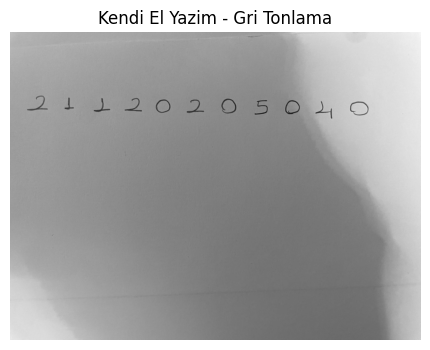

In [126]:


from PIL import Image
import matplotlib.pyplot as plt

# Fotoğrafı aç
filename = list(uploaded.keys())[0]
image = Image.open(filename)

# Fotoğrafı 90 derece saat yönünde döndür
image = image.rotate(-90, expand=True)

# Gri tonlamaya çevir
gray_image = image.convert("L")

# Görüntüyü göster
plt.figure(figsize=(12, 4))
plt.imshow(gray_image, cmap="gray")
plt.title("Kendi El Yazim - Gri Tonlama")
plt.axis("off")
plt.show()


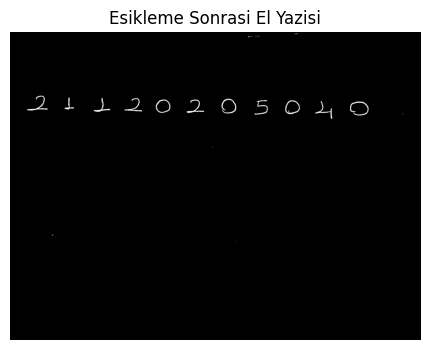

In [127]:

import cv2
import numpy as np
import matplotlib.pyplot as plt

# PIL görüntüsünü NumPy dizisine dönüştür
gray_array = np.array(gray_image)

# Hafif bulanıklaştırma ile gürültüyü azalt
blurred = cv2.GaussianBlur(
    gray_array, (3, 3), 0
)

# Uyarlamalı eşikleme
binary_image = cv2.adaptiveThreshold(
    blurred,
    255,
    cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY_INV,
    31,
    12
)

plt.figure(figsize=(14, 4))
plt.imshow(binary_image, cmap="gray", vmin=0, vmax=255)
plt.title("Esikleme Sonrasi El Yazisi")
plt.axis("off")
plt.show()


Tespit edilen rakam sayisi: 11


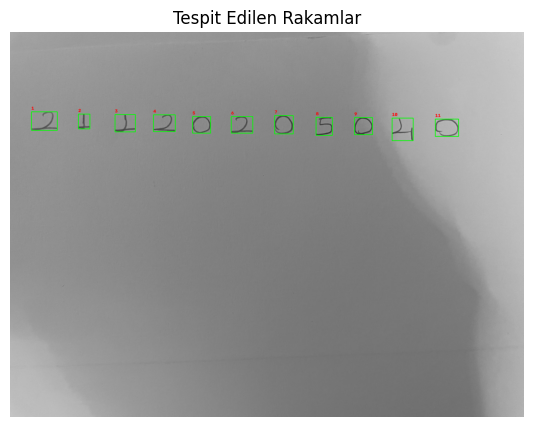

In [128]:

# Görüntüdeki konturları bul
contours, _ = cv2.findContours(
    binary_image,
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_SIMPLE
)

digit_boxes = []

# Çok küçük gürültüleri ele
for contour in contours:

    x, y, w, h = cv2.boundingRect(contour)

    if w >= 8 and h >= 15 and w * h >= 120:
        digit_boxes.append((x, y, w, h))

# Soldan sağa sırala
digit_boxes = sorted(digit_boxes, key=lambda box: box[0])

print("Tespit edilen rakam sayisi:", len(digit_boxes))

# Tespit edilen bölgeleri çiz
preview = cv2.cvtColor(
    gray_array, cv2.COLOR_GRAY2RGB
)

for i, (x, y, w, h) in enumerate(digit_boxes):

    cv2.rectangle(
        preview,
        (x, y),
        (x + w, y + h),
        (0, 255, 0),
        2
    )

    cv2.putText(
        preview,
        str(i + 1),
        (x, max(y - 8, 15)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.6,
        (255, 0, 0),
        2
    )

plt.figure(figsize=(14, 5))
plt.imshow(preview)
plt.title("Tespit Edilen Rakamlar")
plt.axis("off")
plt.show()


İşlenen rakam sayısı: 11


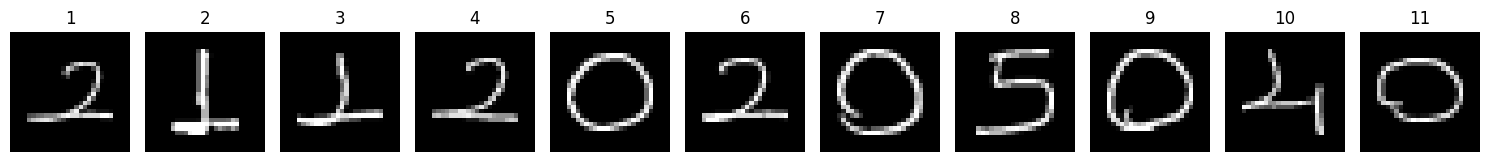

In [129]:

import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
import torch

# İşlenmiş rakamları kaydedeceğimiz klasör
os.makedirs("results/processed_digits", exist_ok=True)

processed_digits = []

for i, (x, y, w, h) in enumerate(digit_boxes):

    # Rakamı siyah-beyaz görüntüden kırp
    digit = binary_image[y:y+h, x:x+w]

    # En-boy oranını koruyarak yeniden boyutlandır
    scale = 20 / max(w, h)

    new_w = max(1, round(w * scale))
    new_h = max(1, round(h * scale))

    resized = cv2.resize(
        digit,
        (new_w, new_h),
        interpolation=cv2.INTER_AREA
    )

    # 28x28 siyah görüntü oluştur
    canvas = np.zeros((28, 28), dtype=np.uint8)

    # Rakamı ortala
    x_offset = (28 - new_w) // 2
    y_offset = (28 - new_h) // 2

    canvas[
        y_offset:y_offset+new_h,
        x_offset:x_offset+new_w
    ] = resized

    # Görüntüyü kaydet
    cv2.imwrite(
        f"results/processed_digits/digit_{i+1:02d}.png",
        canvas
    )

    # 0-1 aralığına normalize et
    normalized = canvas.astype(np.float32) / 255.0

    processed_digits.append(normalized)

print("İşlenen rakam sayısı:", len(processed_digits))

# Rakamları görselleştir
plt.figure(figsize=(15, 3))

for i, digit in enumerate(processed_digits):
    plt.subplot(1, len(processed_digits), i+1)
    plt.imshow(digit, cmap="gray", vmin=0, vmax=1)
    plt.title(str(i+1))
    plt.axis("off")

plt.tight_layout()
plt.show()


In [130]:

import torch
import numpy as np

# En iyi Deney 2 modelini yükle
model2.load_state_dict(
    torch.load(
        "results/experiment2_best_model.pth",
        map_location=device,
        weights_only=True
    )
)

model2.eval()

# 11 rakamı tek bir tensor haline getir
input_array = np.stack(processed_digits)

input_tensor = torch.tensor(
    input_array,
    dtype=torch.float32
).unsqueeze(1).to(device)

# Tahmin yap
with torch.no_grad():
    outputs = model2(input_tensor)

    probabilities = torch.softmax(outputs, dim=1)

    predicted_digits = outputs.argmax(dim=1).cpu().numpy()

    confidence_scores = (
        probabilities.max(dim=1).values.cpu().numpy()
    )

# Gerçek öğrenci numarası
student_number = "21120205040"

print("Gerçek Numara: ", student_number)

predicted_number = "".join(
    str(digit) for digit in predicted_digits
)

print("Tahmin Edilen:", predicted_number)

correct_count = sum(
    str(pred) == actual
    for pred, actual in zip(predicted_digits, student_number)
)

handwriting_accuracy = (
    100 * correct_count / len(student_number)
)

print(f"Doğru Rakam Sayısı: {correct_count}/11")
print(f"El Yazısı Doğruluğu: %{handwriting_accuracy:.2f}")

print("\nRakam Bazında Sonuçlar:")

for i, (actual, pred, confidence) in enumerate(
    zip(student_number, predicted_digits, confidence_scores)
):
    status = "DOGRU" if actual == str(pred) else "YANLIS"

    print(
        f"{i+1}. rakam | "
        f"Gerçek: {actual} | "
        f"Tahmin: {pred} | "
        f"Güven: %{confidence*100:.2f} | "
        f"{status}"
    )


Gerçek Numara:  21120205040
Tahmin Edilen: 21120205020
Doğru Rakam Sayısı: 10/11
El Yazısı Doğruluğu: %90.91

Rakam Bazında Sonuçlar:
1. rakam | Gerçek: 2 | Tahmin: 2 | Güven: %96.53 | DOGRU
2. rakam | Gerçek: 1 | Tahmin: 1 | Güven: %92.62 | DOGRU
3. rakam | Gerçek: 1 | Tahmin: 1 | Güven: %96.54 | DOGRU
4. rakam | Gerçek: 2 | Tahmin: 2 | Güven: %99.23 | DOGRU
5. rakam | Gerçek: 0 | Tahmin: 0 | Güven: %96.35 | DOGRU
6. rakam | Gerçek: 2 | Tahmin: 2 | Güven: %98.69 | DOGRU
7. rakam | Gerçek: 0 | Tahmin: 0 | Güven: %99.83 | DOGRU
8. rakam | Gerçek: 5 | Tahmin: 5 | Güven: %99.97 | DOGRU
9. rakam | Gerçek: 0 | Tahmin: 0 | Güven: %94.40 | DOGRU
10. rakam | Gerçek: 4 | Tahmin: 2 | Güven: %71.39 | YANLIS
11. rakam | Gerçek: 0 | Tahmin: 0 | Güven: %88.41 | DOGRU


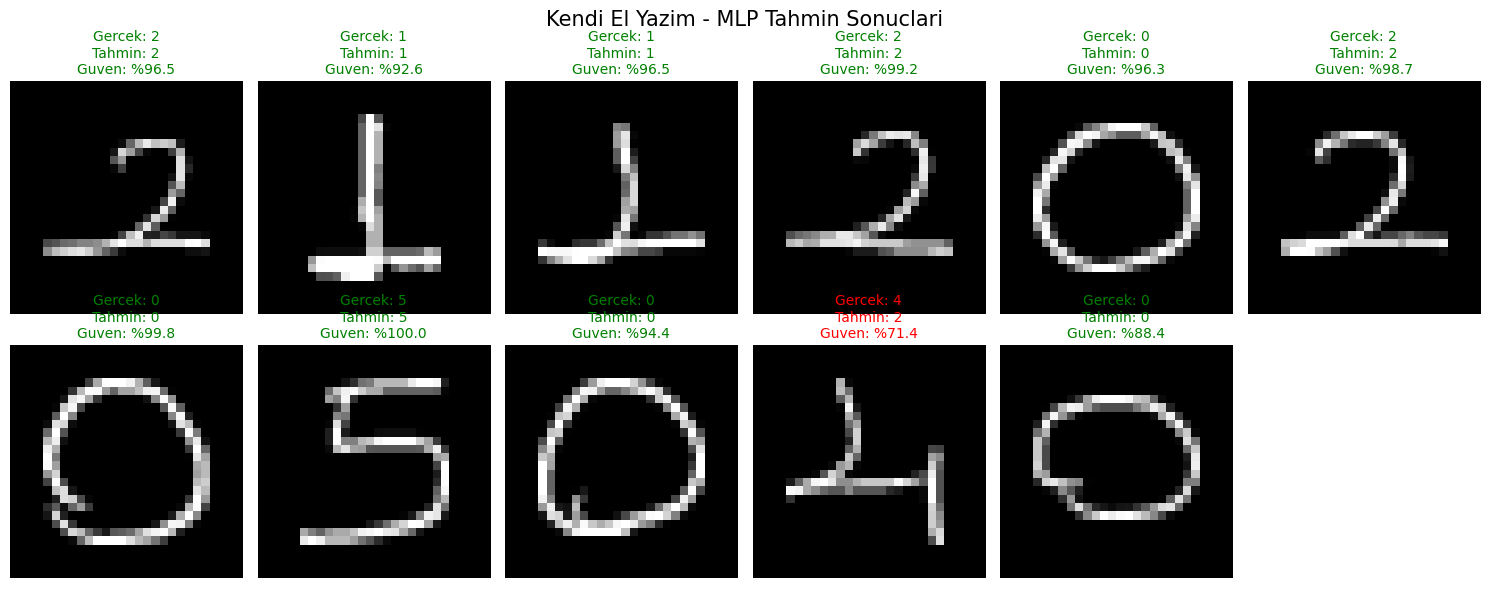

El yazisi tahmin gorseli kaydedildi.


In [132]:
import matplotlib.pyplot as plt
import os

os.makedirs("results", exist_ok=True)

fig, axes = plt.subplots(2, 6, figsize=(15, 6))
axes = axes.flatten()

for i, digit in enumerate(processed_digits):

    # Görüntüyü 0-255 aralığına geri çekerek çizdirelim
    axes[i].imshow(digit, cmap="gray", vmin=0, vmax=1)

    real = student_number[i]
    predicted = str(predicted_digits[i])

    is_correct = real == predicted

    color = "green" if is_correct else "red"

    axes[i].set_title(
        f"Gercek: {real}\n"
        f"Tahmin: {predicted}\n"
        f"Guven: %{confidence_scores[i]*100:.1f}",
        color=color,
        fontsize=10
    )

    axes[i].axis("off")

# Kullanılmayan son kutuyu gizle
for j in range(len(processed_digits), len(axes)):
    axes[j].axis("off")

plt.suptitle(
    "Kendi El Yazim - MLP Tahmin Sonuclari",
    fontsize=15
)

plt.tight_layout()

plt.savefig(
    "results/handwriting_predictions.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("El yazisi tahmin gorseli kaydedildi.")

In [133]:

import os
import shutil
from google.colab import files

# Proje klasörlerini kontrol et
for folder in ["results", "handwriting"]:
    if os.path.exists(folder):
        print(f"{folder}: Mevcut")
        print("Dosya sayisi:",
              sum(len(f) for _, _, f in os.walk(folder)))
    else:
        print(f"{folder}: Bulunamadi")

# Klasörleri ZIP dosyasına ekle
with __import__("zipfile").ZipFile(
    "MNIST_MLP_Project_Files.zip", "w"
) as zip_file:

    for folder in ["results", "handwriting"]:
        if os.path.exists(folder):
            for root, dirs, filenames in os.walk(folder):
                for filename in filenames:
                    full_path = os.path.join(root, filename)
                    zip_file.write(full_path)

# Orijinal el yazısı fotoğrafını da ekle
if os.path.exists(filename):
    with __import__("zipfile").ZipFile(
        "MNIST_MLP_Project_Files.zip", "a"
    ) as zip_file:
        zip_file.write(
            filename,
            arcname="handwriting/student_number_original.jpg"
        )

print("ZIP dosyasi hazir!")
files.download("MNIST_MLP_Project_Files.zip")


results: Mevcut
Dosya sayisi: 21
handwriting: Bulunamadi
ZIP dosyasi hazir!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>